In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import os, glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import kagglehub

PROJECT_DIR = "/content/drive/MyDrive/iris_project"
os.makedirs(PROJECT_DIR, exist_ok=True)

# download from Kaggle by code and find the CSV file
path = kagglehub.dataset_download("arshid/iris-flower-dataset")
csv_files = glob.glob(f"{path}/**/*.csv", recursive=True)
print("Files found:", csv_files)

df = pd.read_csv(csv_files[0])
print("\nShape:", df.shape)
print("\nFirst 5 records:")
print(df.head())

print("\nColumns and types:")
print(df.dtypes)
print("\nMissing values per column:")
print(df.isnull().sum())
print("\nDuplicate rows:", df.duplicated().sum())

target = df.columns[-1]                      # the species column is the last one
print(f"\nClass counts for '{target}':")
print(df[target].value_counts())

print("\nSummary statistics:")
print(df.describe().round(2))

Mounted at /content/drive
Using Colab cache for faster access to the 'iris-flower-dataset' dataset.
Files found: ['/kaggle/input/iris-flower-dataset/IRIS.csv']

Shape: (150, 5)

First 5 records:
   sepal_length  sepal_width  petal_length  petal_width      species
0           5.1          3.5           1.4          0.2  Iris-setosa
1           4.9          3.0           1.4          0.2  Iris-setosa
2           4.7          3.2           1.3          0.2  Iris-setosa
3           4.6          3.1           1.5          0.2  Iris-setosa
4           5.0          3.6           1.4          0.2  Iris-setosa

Columns and types:
sepal_length    float64
sepal_width     float64
petal_length    float64
petal_width     float64
species          object
dtype: object

Missing values per column:
sepal_length    0
sepal_width     0
petal_length    0
petal_width     0
species         0
dtype: int64

Duplicate rows: 3

Class counts for 'species':
species
Iris-setosa        50
Iris-versicolor    50
Iris-v

Duplicated rows:
      sepal_length  sepal_width  petal_length  petal_width         species
9             4.9          3.1           1.5          0.1     Iris-setosa
34            4.9          3.1           1.5          0.1     Iris-setosa
37            4.9          3.1           1.5          0.1     Iris-setosa
101           5.8          2.7           5.1          1.9  Iris-virginica
142           5.8          2.7           5.1          1.9  Iris-virginica 

Shape after cleaning: (147, 5)
species
versicolor    50
virginica     49
setosa        48
Name: count, dtype: int64 

            sepal_length  sepal_width  petal_length  petal_width
species                                                         
setosa              5.01         3.43          1.46         0.25
versicolor          5.94         2.77          4.26         1.33
virginica           6.60         2.98          5.56         2.03 



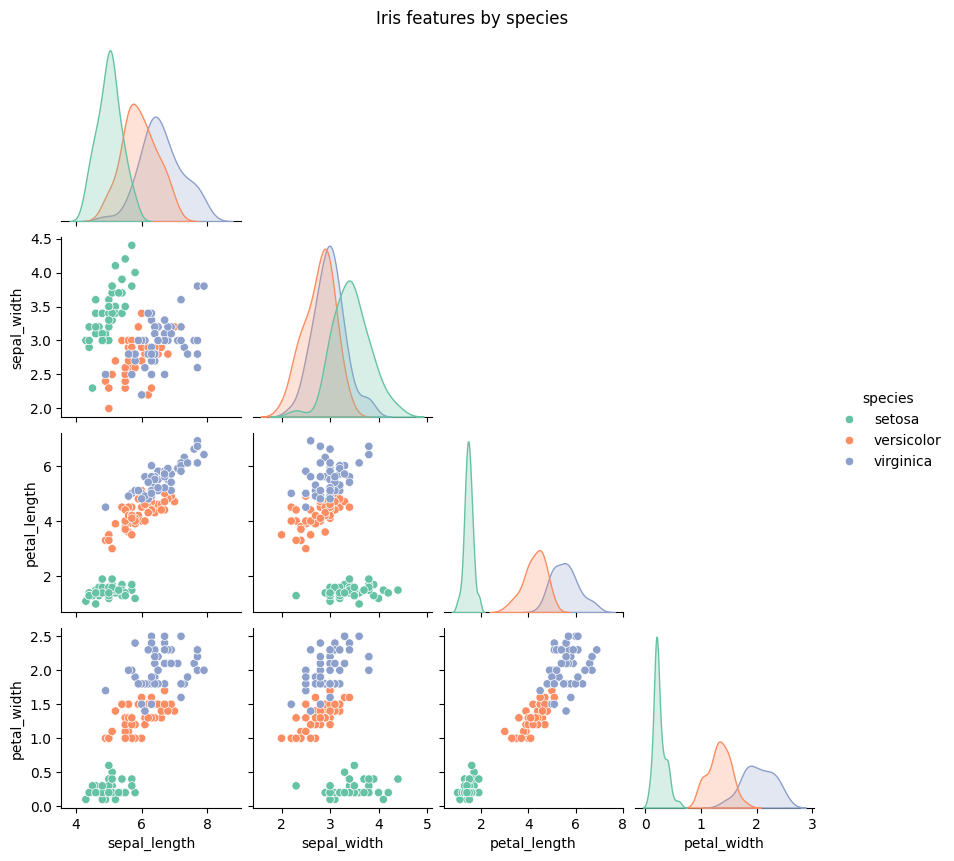

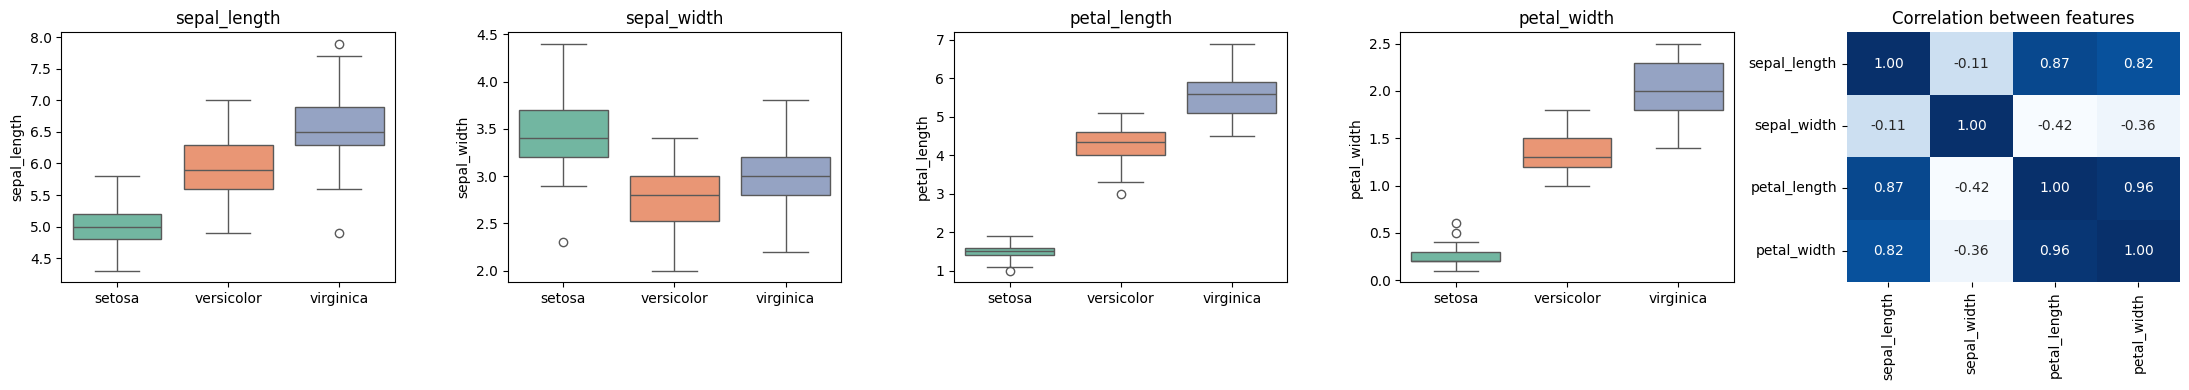

In [ ]:
# 1. cleaning: drop duplicate rows and shorten the species names
print("Duplicated rows:\n", df[df.duplicated(keep=False)].sort_values(list(df.columns)), "\n")
df = df.drop_duplicates().reset_index(drop=True)
df["species"] = df["species"].str.replace("Iris-", "", regex=False)
FEATURES = ["sepal_length", "sepal_width", "petal_length", "petal_width"]
print("Shape after cleaning:", df.shape)
print(df["species"].value_counts(), "\n")
df.to_csv(f"{PROJECT_DIR}/iris_clean.csv", index=False)

# 2. average measurements per species
print(df.groupby("species")[FEATURES].mean().round(2), "\n")

# 3. pair plot: every feature against every other, coloured by species
g = sns.pairplot(df, hue="species", corner=True, height=2.1, palette="Set2")
g.fig.suptitle("Iris features by species", y=1.02)
g.savefig(f"{PROJECT_DIR}/pairplot.png", dpi=150, bbox_inches="tight")
plt.show()

# 4. box plots per feature and correlation heatmap
fig, ax = plt.subplots(1, 5, figsize=(22, 4))
for a, f in zip(ax[:4], FEATURES):
    sns.boxplot(data=df, x="species", y=f, hue="species", palette="Set2", legend=False, ax=a)
    a.set_title(f); a.set_xlabel("")
sns.heatmap(df[FEATURES].corr(), annot=True, fmt=".2f", cmap="Blues", ax=ax[4], cbar=False)
ax[4].set_title("Correlation between features")
plt.tight_layout()
plt.savefig(f"{PROJECT_DIR}/boxplots_correlation.png", dpi=150)
plt.show()

Classes: {'setosa': np.int64(0), 'versicolor': np.int64(1), 'virginica': np.int64(2)}
Train: (117, 4) | Test: (30, 4)
Train class counts: [38 40 39] | Test class counts: [10 10 10]

Cross-validation on the training set (5-fold x 5 repeats):
              Model  CV accuracy    Std
Logistic Regression       0.9588 0.0351
          SVM (RBF)       0.9588 0.0372
        Naive Bayes       0.9555 0.0407
      Random Forest       0.9469 0.0372
          KNN (k=5)       0.9467 0.0375
      Decision Tree       0.9367 0.0405


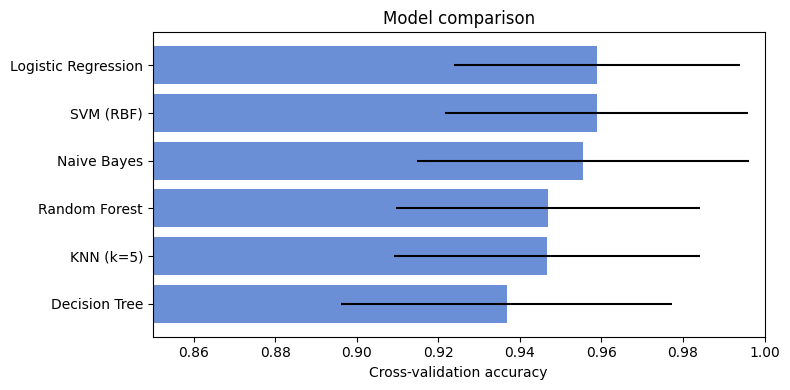

In [3]:
from sklearn.model_selection import train_test_split, RepeatedStratifiedKFold, cross_val_score
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.naive_bayes import GaussianNB

# 1. encode the species names as numbers and make a stratified 80/20 split
le = LabelEncoder()
X = df[FEATURES].values
y = le.fit_transform(df["species"])
print("Classes:", dict(zip(le.classes_, le.transform(le.classes_))))

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)
print(f"Train: {X_train.shape} | Test: {X_test.shape}")
print("Train class counts:", np.bincount(y_train), "| Test class counts:", np.bincount(y_test))

# save the split so it is identical in every later session
pd.concat([pd.DataFrame(X_train, columns=FEATURES).assign(species=le.inverse_transform(y_train), split="train"),
           pd.DataFrame(X_test,  columns=FEATURES).assign(species=le.inverse_transform(y_test),  split="test")]) \
  .to_csv(f"{PROJECT_DIR}/split.csv", index=False)

# 2. compare six models; scaling is inside each pipeline so it is fitted on the training folds only
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "KNN (k=5)":           KNeighborsClassifier(5),
    "SVM (RBF)":           SVC(),
    "Decision Tree":       DecisionTreeClassifier(random_state=42),
    "Random Forest":       RandomForestClassifier(n_estimators=200, random_state=42),
    "Naive Bayes":         GaussianNB(),
}
cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=5, random_state=42)
rows = []
for name, m in models.items():
    s = cross_val_score(make_pipeline(StandardScaler(), m), X_train, y_train, cv=cv, scoring="accuracy")
    rows.append((name, s.mean(), s.std()))
res = pd.DataFrame(rows, columns=["Model", "CV accuracy", "Std"]).sort_values("CV accuracy", ascending=False).reset_index(drop=True)
print("\nCross-validation on the training set (5-fold x 5 repeats):")
print(res.round(4).to_string(index=False))

res.to_csv(f"{PROJECT_DIR}/cv_results.csv", index=False)
plt.figure(figsize=(8, 4))
plt.barh(res["Model"][::-1], res["CV accuracy"][::-1], xerr=res["Std"][::-1], color="#6b8fd6")
plt.xlim(0.85, 1.0); plt.xlabel("Cross-validation accuracy"); plt.title("Model comparison")
plt.tight_layout()
plt.savefig(f"{PROJECT_DIR}/model_comparison.png", dpi=150)
plt.show()

Best C: 10 | CV accuracy: 0.9604
 param_logisticregression__C  mean_test_score  std_test_score
                        0.01           0.8872          0.0583
                        0.10           0.9128          0.0618
                        1.00           0.9588          0.0351
                       10.00           0.9604          0.0400
                      100.00           0.9604          0.0418

Test accuracy: 1.0000  (30 of 30 correct)

              precision    recall  f1-score   support

      setosa     1.0000    1.0000    1.0000        10
  versicolor     1.0000    1.0000    1.0000        10
   virginica     1.0000    1.0000    1.0000        10

    accuracy                         1.0000        30
   macro avg     1.0000    1.0000    1.0000        30
weighted avg     1.0000    1.0000    1.0000        30



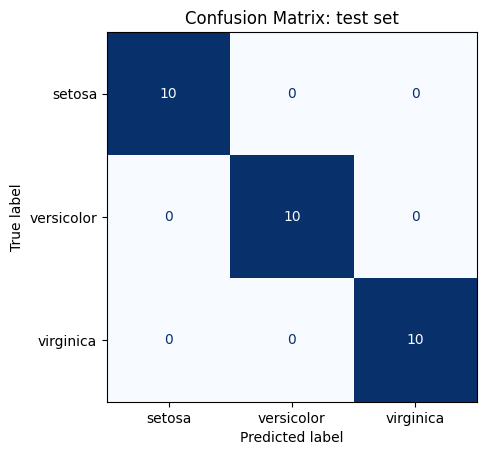


Logistic Regression coefficients (standardised features):
            sepal_length  sepal_width  petal_length  petal_width
setosa             -1.75         1.73         -3.34        -3.17
versicolor          1.10        -0.30         -1.10        -1.42
virginica           0.65        -1.43          4.44         4.59

Saved the model to Drive.


In [4]:
import joblib
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import (accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay)

# 1. tune the regularisation strength C by cross-validation on the training set only
pipe = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))
grid = GridSearchCV(pipe, {"logisticregression__C": [0.01, 0.1, 1, 10, 100]}, cv=cv, scoring="accuracy")
grid.fit(X_train, y_train)
print("Best C:", grid.best_params_["logisticregression__C"], "| CV accuracy:", round(grid.best_score_, 4))
print(pd.DataFrame(grid.cv_results_)[["param_logisticregression__C", "mean_test_score", "std_test_score"]].round(4).to_string(index=False))

# 2. the final model (refitted on all training data) is tested ONCE on the 30 held-out flowers
model = grid.best_estimator_
y_pred = model.predict(X_test)
print(f"\nTest accuracy: {accuracy_score(y_test, y_pred):.4f}  ({int((y_pred == y_test).sum())} of {len(y_test)} correct)\n")
print(classification_report(y_test, y_pred, target_names=le.classes_, digits=4))

ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred), display_labels=le.classes_).plot(cmap="Blues", colorbar=False)
plt.title("Confusion Matrix: test set")
plt.savefig(f"{PROJECT_DIR}/confusion_matrix.png", dpi=150, bbox_inches="tight")
plt.show()

# 3. which measurements matter: coefficients on the standardised features
coef = pd.DataFrame(model[-1].coef_, index=le.classes_, columns=FEATURES)
print("\nLogistic Regression coefficients (standardised features):")
print(coef.round(2))

# 4. save the model and the label encoder to Drive
joblib.dump({"model": model, "label_encoder": le, "features": FEATURES}, f"{PROJECT_DIR}/iris_model.joblib")
print("\nSaved the model to Drive.")

In [5]:
from google.colab import drive
drive.mount('/content/drive')

import numpy as np, pandas as pd, joblib
import matplotlib.pyplot as plt
from ipywidgets import FloatSlider, VBox, interactive_output
from IPython.display import display

PROJECT_DIR = "/content/drive/MyDrive/iris_project"
saved = joblib.load(f"{PROJECT_DIR}/iris_model.joblib")
model, le, FEATURES = saved["model"], saved["label_encoder"], saved["features"]
data = pd.read_csv(f"{PROJECT_DIR}/iris_clean.csv")

# 1. predictions for new flowers (measurements in cm) that were not in the dataset
new = pd.DataFrame([
    [5.0, 3.4, 1.5, 0.2],      # looks like setosa
    [5.9, 2.8, 4.3, 1.3],      # looks like versicolor
    [6.7, 3.0, 5.6, 2.1],      # looks like virginica
    [6.0, 2.7, 5.0, 1.6],      # borderline: between versicolor and virginica
], columns=FEATURES)
probs = model.predict_proba(new.values)
out = new.copy()
out["prediction"] = le.inverse_transform(probs.argmax(axis=1))
for i, c in enumerate(le.classes_):
    out[f"P({c})"] = probs[:, i].round(3)
print(out.to_string(index=False))

# 2. interactive sliders: change the four measurements and see the prediction update
def show(**kw):
    x = np.array([[kw[f] for f in FEATURES]])
    p = model.predict_proba(x)[0]
    k = int(p.argmax())
    plt.figure(figsize=(6, 2.4))
    plt.barh(le.classes_, p, color=["#8fd0b9" if i == k else "#cfd6e4" for i in range(len(p))])
    plt.xlim(0, 1); plt.xlabel("Probability")
    plt.title(f"Prediction: {le.classes_[k]} ({p[k]*100:.1f}%)")
    plt.tight_layout(); plt.show()

sliders = {f: FloatSlider(value=round(float(data[f].median()), 1), min=float(data[f].min()), max=float(data[f].max()),
                          step=0.1, description=f.replace("_", " "), style={"description_width": "100px"},
                          layout={"width": "420px"}) for f in FEATURES}
display(VBox(list(sliders.values())), interactive_output(show, sliders))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
 sepal_length  sepal_width  petal_length  petal_width prediction  P(setosa)  P(versicolor)  P(virginica)
          5.0          3.4           1.5          0.2     setosa      0.997          0.003         0.000
          5.9          2.8           4.3          1.3 versicolor      0.002          0.986         0.012
          6.7          3.0           5.6          2.1  virginica      0.000          0.006         0.994
          6.0          2.7           5.0          1.6  virginica      0.000          0.418         0.582


Output()

In [9]:
from google.colab import drive, output
drive.mount('/content/drive')

import json
import numpy as np, pandas as pd, joblib
from IPython.display import HTML, JSON, display

PROJECT_DIR = "/content/drive/MyDrive/iris_project"
saved = joblib.load(f"{PROJECT_DIR}/iris_model.joblib")
model, le, FEATURES = saved["model"], saved["label_encoder"], saved["features"]
data = pd.read_csv(f"{PROJECT_DIR}/iris_clean.csv")

# ---------- Python side: the saved model answers each request from the page ----------
def predict_flower(payload):
    try:
        v = json.loads(payload)
        x = np.array([[float(v[f]) for f in FEATURES]])
        p = model.predict_proba(x)[0]
        return JSON({"classes": [str(c) for c in le.classes_], "probs": [float(a) for a in p]})
    except Exception as e:
        return JSON({"error": str(e)})

output.register_callback("iris.predict", predict_flower)

RANGES = {f: [float(np.floor(data[f].min() * 10) / 10), float(np.ceil(data[f].max() * 10) / 10)] for f in FEATURES}
POINTS = data[["petal_length", "petal_width", "species"]].round(2).values.tolist()

# ---------- Browser side: layout, sliders, chart ----------
UI = r"""
<style>
#ir{--ink:#1f2937;--mut:#6b7280;--line:#e5e7eb;--bg:#f6f7fb;--c0:#1b9e77;--c1:#d95f02;--c2:#7570b3;
 font-family:-apple-system,Segoe UI,Roboto,Arial,sans-serif;color:var(--ink);background:var(--bg);border-radius:14px;padding:18px;max-width:900px;box-sizing:border-box}
#ir *{box-sizing:border-box}
#ir h1{margin:0;font-size:22px;font-weight:700;color:#1f2937 !important}
#ir .sub{color:var(--mut);font-size:13px;margin:4px 0 16px}
#ir .grid{display:grid;grid-template-columns:1fr 1fr;gap:14px}
@media(max-width:700px){#ir .grid{grid-template-columns:1fr}}
#ir .card{background:#fff;border:1px solid var(--line);border-radius:12px;padding:16px}
#ir .card h2{margin:0 0 12px;font-size:12px;letter-spacing:.06em;text-transform:uppercase;color:var(--mut) !important;font-weight:600}
#ir .row{margin-bottom:14px}
#ir .row .top{display:flex;justify-content:space-between;font-size:14px;margin-bottom:4px}
#ir .row .top b{font-variant-numeric:tabular-nums}
#ir input[type=range]{width:100%;accent-color:#4f46e5}
#ir .presets{display:flex;flex-wrap:wrap;gap:8px;margin-top:4px}
#ir .presets button{border:1px solid var(--line);background:#fff;border-radius:999px;padding:6px 12px;font-size:12.5px;cursor:pointer;color:var(--ink)}
#ir .presets button:hover{background:#f3f4f6}
#ir .res{display:flex;align-items:center;gap:12px;margin-bottom:12px}
#ir .dot{width:14px;height:14px;border-radius:50%;background:#ccc;flex:none}
#ir .name{font-size:24px;font-weight:700;line-height:1.1}
#ir .conf{font-size:13px;color:var(--mut)}
#ir .bar{display:flex;align-items:center;gap:8px;margin:7px 0;font-size:13px}
#ir .bar .l{width:84px}
#ir .bar .t{flex:1;height:12px;background:#eef0f4;border-radius:6px;overflow:hidden}
#ir .bar .f{height:100%;width:0;border-radius:6px;transition:width .25s}
#ir .bar .v{width:48px;text-align:right;font-variant-numeric:tabular-nums}
#ir .note{font-size:12.5px;color:#92400e;background:#fffbeb;border:1px solid #fde68a;border-radius:8px;padding:7px 10px;margin-top:8px;display:none}
#ir .legend{display:flex;gap:14px;font-size:12px;color:var(--mut);margin-top:6px;flex-wrap:wrap}
#ir .legend i{display:inline-block;width:9px;height:9px;border-radius:50%;margin-right:5px}
#ir .foot{font-size:11.5px;color:var(--mut);margin-top:12px}
#ir svg text{font-family:inherit}
</style>
<div id="ir">
  <h1>Iris Flower Classifier</h1>
  <div class="sub">Logistic Regression trained on 147 flowers &middot; about 96% cross-validation accuracy</div>
  <div class="grid">
    <div class="card">
      <h2>Flower measurements</h2>
      <div id="ir-sliders"></div>
      <h2 style="margin-top:6px">Try an example</h2>
      <div class="presets" id="ir-presets"></div>
    </div>
    <div class="card">
      <h2>Prediction</h2>
      <div class="res"><span class="dot" id="ir-dot"></span><div><div class="name" id="ir-name">...</div><div class="conf" id="ir-conf">&nbsp;</div></div></div>
      <div id="ir-bars"></div>
      <div class="note" id="ir-note">Low confidence: this flower sits between two species.</div>
    </div>
  </div>
  <div class="card" style="margin-top:14px">
    <h2>Where your flower falls among the 147 flowers in the dataset</h2>
    <svg id="ir-plot" viewBox="0 0 640 300" width="100%" style="max-width:640px;display:block;margin:0 auto"></svg>
    <div class="legend" id="ir-legend" style="justify-content:center"></div>
  </div>
  <div class="foot">Educational project: not for botanical or any other real-world identification.</div>
</div>
<script>
(function(){
  const F = ["sepal_length","sepal_width","petal_length","petal_width"];
  const LAB = {sepal_length:"Sepal length",sepal_width:"Sepal width",petal_length:"Petal length",petal_width:"Petal width"};
  const R = __RANGES__, PTS = __POINTS__;
  const COL = {"setosa":"#1b9e77","versicolor":"#d95f02","virginica":"#7570b3"};
  const SP = ["setosa","versicolor","virginica"];
  const PRE = {"Typical setosa":[5.0,3.4,1.5,0.2],"Typical versicolor":[5.9,2.8,4.3,1.3],"Typical virginica":[6.7,3.0,5.6,2.1],"Borderline":[6.0,2.7,5.0,1.6]};
  const $ = id => document.getElementById(id);
  const val = {}, sl = {}, lab = {};

  // sliders
  F.forEach((f,i)=>{
    const med = [5.8,3.0,4.4,1.3][i]; val[f]=med;
    const row = document.createElement("div"); row.className="row";
    row.innerHTML = '<div class="top"><span>'+LAB[f]+'</span><b></b></div><input type="range">';
    const inp = row.querySelector("input"); inp.min=R[f][0]; inp.max=R[f][1]; inp.step=0.1; inp.value=med;
    sl[f]=inp; lab[f]=row.querySelector("b");
    inp.addEventListener("input",()=>{val[f]=parseFloat(inp.value); update();});
    $("ir-sliders").appendChild(row);
  });
  // presets
  Object.keys(PRE).forEach(n=>{
    const b=document.createElement("button"); b.textContent=n;
    b.onclick=()=>{F.forEach((f,i)=>{val[f]=PRE[n][i]; sl[f].value=PRE[n][i];}); update();};
    $("ir-presets").appendChild(b);
  });
  // bars
  SP.forEach(s=>{
    const d=document.createElement("div"); d.className="bar";
    d.innerHTML='<span class="l">'+s+'</span><span class="t"><span class="f" id="ir-f-'+s+'" style="display:block;background:'+COL[s]+'"></span></span><span class="v" id="ir-v-'+s+'">0%</span>';
    $("ir-bars").appendChild(d);
  });
  // legend
  $("ir-legend").innerHTML = SP.map(s=>'<span><i style="background:'+COL[s]+'"></i>'+s+'</span>').join("")+'<span><i style="background:#fff;border:2px solid #111"></i>your flower</span>';

  // plot: petal length (x) vs petal width (y)
  const W=640,H=300,L=52,B=38,T=12,Rr=14, XR=[0.5,7.2], YR=[0,2.8];
  const X=v=>L+(v-XR[0])/(XR[1]-XR[0])*(W-L-Rr), Y=v=>H-B-(v-YR[0])/(YR[1]-YR[0])*(H-B-T);
  let g='';
  for(let t=1;t<=7;t++){g+='<line x1="'+X(t)+'" x2="'+X(t)+'" y1="'+T+'" y2="'+(H-B)+'" stroke="#eef0f4"/><text x="'+X(t)+'" y="'+(H-B+16)+'" font-size="11" text-anchor="middle" fill="#6b7280">'+t+'</text>';}
  for(let t=0;t<=2.5;t+=0.5){g+='<line x1="'+L+'" x2="'+(W-Rr)+'" y1="'+Y(t)+'" y2="'+Y(t)+'" stroke="#eef0f4"/><text x="'+(L-8)+'" y="'+(Y(t)+4)+'" font-size="11" text-anchor="end" fill="#6b7280">'+t+'</text>';}
  g+='<text x="'+((L+W-Rr)/2)+'" y="'+(H-6)+'" font-size="12" text-anchor="middle" fill="#374151">Petal length (cm)</text>';
  g+='<text transform="translate(14,'+((T+H-B)/2)+') rotate(-90)" font-size="12" text-anchor="middle" fill="#374151">Petal width (cm)</text>';
  PTS.forEach(p=>{g+='<circle cx="'+X(p[0])+'" cy="'+Y(p[1])+'" r="3.6" fill="'+COL[p[2]]+'" fill-opacity=".55"/>';});
  g+='<g id="ir-me"><circle r="11" fill="#fff" fill-opacity=".85" stroke="#111" stroke-width="2.2"/><circle r="3" fill="#111"/></g>';
  $("ir-plot").innerHTML=g;

  let seq=0;
  function update(){
    F.forEach(f=>{lab[f].textContent=val[f].toFixed(1)+" cm";});
    const me=$("ir-me"); me.setAttribute("transform","translate("+X(val.petal_length)+","+Y(val.petal_width)+")");
    const my=++seq;
    google.colab.kernel.invokeFunction("iris.predict",[JSON.stringify(val)],{}).then(res=>{
      if(my!==seq) return;
      const d=res.data["application/json"];
      if(d.error){$("ir-name").textContent="Error"; $("ir-conf").textContent=d.error; return;}
      let k=0; d.probs.forEach((p,i)=>{ if(p>d.probs[k]) k=i; });
      d.classes.forEach((c,i)=>{ $("ir-f-"+c).style.width=(d.probs[i]*100).toFixed(1)+"%"; $("ir-v-"+c).textContent=(d.probs[i]*100).toFixed(1)+"%"; });
      const c=d.classes[k];
      $("ir-name").textContent="Iris "+c; $("ir-conf").textContent=(d.probs[k]*100).toFixed(1)+"% confidence";
      $("ir-dot").style.background=COL[c];
      $("ir-note").style.display = d.probs[k]<0.75 ? "block":"none";
    });
  }
  update();
})();
</script>
"""
display(HTML(UI.replace("__RANGES__", json.dumps(RANGES)).replace("__POINTS__", json.dumps(POINTS))))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
